In [1]:
import os
import csv
import random
import shutil
import warnings
import itertools

import numpy as np
import pandas as pd

try:
    import cv2
except ImportError:
    import subprocess
    import sys
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless'],
        check=True
    )
    import cv2

import seaborn as sns
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, WeightedRandomSampler

from sklearn.metrics import classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [2]:
# --- Paths & dataset location -------------------------------------------
# This reconstructs the setup that cell 1 (the kagglehub download) and
# split_dataset() rely on but that wasn't defined anywhere in the notebook
# as handed over — SEED, ROOT_DIR, SEARCH_DIRS, CLASS_SOURCE_DIR,
# find_class_source_dir and _dir_has_images. It's inferred from how those
# names are used (a search list of candidate directories, resolved down to
# the one that actually holds the four raw class folders).

SEED = 42
ROOT_DIR = 'data/COVID-19_Radiography_Dataset'
CLASS_NAMES = ['normal', 'pneumonia', 'covid_19', 'lung_opacity']
RAW_CLASS_DIRS = ['Normal', 'Viral Pneumonia', 'COVID', 'Lung_Opacity']
# maps a split class folder name back to its raw source folder name, e.g.
# 'covid_19' -> 'COVID' — used below to locate each image's original raw
# folder (and, for the GradCAM faithfulness check, its lung mask).
CLASS_TO_RAW_DIR = dict(zip(CLASS_NAMES, RAW_CLASS_DIRS))

# If you already have the raw (un-split) dataset somewhere on disk, point
# this at it and it'll be searched too.
EXTRA_SEARCH_DIR = None
SEARCH_DIRS = [d for d in [ROOT_DIR, EXTRA_SEARCH_DIR] if d is not None]

# make sure every directory fit()/plot_summary()/plot_confmat()/etc. below
# will try to write into actually exists
for _d in ('models', 'outputs/CSVs', 'outputs/summary_plots',
           'outputs/confusion_matrices', 'outputs/gradcam'):
    os.makedirs(_d, exist_ok=True)


def _dir_has_images(path):
    """True if `path` exists and contains at least one .png file, either
    directly inside it (a raw class folder) or inside one of its
    subfolders (an already-split train/val/test folder, which nests
    images one level deeper under each class name)."""
    if not os.path.isdir(path):
        return False
    for _, _, files in os.walk(path):
        if any(f.lower().endswith('png') for f in files):
            return True
    return False


def find_class_source_dir(search_dirs):
    """Looks through `search_dirs` (and their immediate subfolders, since
    kagglehub sometimes nests the dataset one level deeper than expected)
    for a folder that directly contains all four raw class folders."""
    candidates = []
    for d in search_dirs:
        if d is None or not os.path.isdir(d):
            continue
        candidates.append(d)
        candidates.extend(
            os.path.join(d, sub) for sub in os.listdir(d)
            if os.path.isdir(os.path.join(d, sub))
        )

    for c in candidates:
        if all(os.path.isdir(os.path.join(c, cls)) for cls in RAW_CLASS_DIRS):
            return c
    return None


CLASS_SOURCE_DIR = find_class_source_dir(SEARCH_DIRS)

In [3]:
# --- utils.py: transforms -------------------------------------------------
# The original main notebook used a bare `transforms.ToTensor()` for every
# split, which drops the Resize(224, 224) and ImageNet Normalize() the
# pretrained backbones and GradCAM's deprocess_image() both expect. Restored
# here to match utils.py (and the commented-out line at the top of the
# dataset-download cell, which shows this was the intended behavior).
transform = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ]),
    'eval': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])
}

In [4]:
# --- utils.py: training / evaluation helpers -------------------------------
def get_num_correct(preds, labels):
    return preds.argmax(dim=1).eq(labels).sum().item()


def get_all_preds(model, loader):
    model.eval()
    with torch.no_grad():
        all_preds = torch.tensor([], device=device)
        for batch in loader:
            images = batch[0].to(device)
            preds = model(images)
            all_preds = torch.cat((all_preds, preds), dim=0)

    return all_preds


def get_confmat(targets, preds):
    stacked = torch.stack(
        (torch.as_tensor(targets, device=device),
         preds.argmax(dim=1)), dim=1
    ).tolist()
    confmat = torch.zeros(4, 4, dtype=torch.int16)
    for t, p in stacked:
        confmat[t, p] += 1

    return confmat


def get_results(confmat, classes):
    results = {}
    d = confmat.diagonal()
    for i, l in enumerate(classes):
        tp = d[i].item()
        tn = d.sum().item() - tp
        fp = confmat[i].sum().item() - tp
        fn = confmat[:, i].sum().item() - tp

        accuracy = (tp + tn) / (tp + tn + fp + fn)
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        f1score = (2 * precision * recall) / (precision + recall) if (precision + recall) else 0.0

        results[l] = [accuracy, recall, precision, f1score]

    return results


def fit(epochs, model, criterion, optimizer, train_dl, valid_dl, patience=5):
    """`patience` is the number of consecutive epochs allowed with no
    improvement in valid_loss before training stops early. Set patience=None
    (or >= epochs) to disable early stopping and always run the full
    `epochs` count."""
    model_name = type(model).__name__.lower()
    valid_loss_min = np.inf
    epochs_no_improve = 0
    # NOTE: originally hard-coded as `len_train, len_valid = 20685, 240`,
    # which silently breaks if the split ever changes. Reads the real
    # dataset sizes off the dataloaders instead.
    len_train, len_valid = len(train_dl.dataset), len(valid_dl.dataset)
    fields = [
        'epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'
    ]
    rows = []

    for epoch in range(epochs):
        train_loss, train_correct = 0, 0
        train_loop = tqdm(train_dl)

        model.train()
        for batch in train_loop:
            images, labels = batch[0].to(device), batch[1].to(device)
            preds = model(images)
            loss = criterion(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            train_correct += get_num_correct(preds, labels)

            train_loop.set_description(f'Epoch [{epoch+1:2d}/{epochs}]')
            train_loop.set_postfix(
                loss=loss.item(), acc=train_correct / len_train
            )
        train_loss = train_loss / len_train
        train_acc = train_correct / len_train

        model.eval()
        with torch.no_grad():
            valid_loss, valid_correct = 0, 0
            for batch in valid_dl:
                images, labels = batch[0].to(device), batch[1].to(device)
                preds = model(images)
                loss = criterion(preds, labels)
                valid_loss += loss.item() * labels.size(0)
                valid_correct += get_num_correct(preds, labels)

            valid_loss = valid_loss / len_valid
            valid_acc = valid_correct / len_valid

            rows.append([epoch, train_loss, train_acc, valid_loss, valid_acc])

            train_loop.write(
                f'\n\t\tAvg train loss: {train_loss:.6f}', end='\t'
            )
            train_loop.write(f'Avg valid loss: {valid_loss:.6f}\n')

            # save model if validation loss has decreased
            if valid_loss <= valid_loss_min:
                train_loop.write('\t\tvalid_loss decreased', end=' ')
                train_loop.write(f'({valid_loss_min:.6f} -> {valid_loss:.6f})')
                train_loop.write('\t\tsaving model...\n')
                torch.save(
                    model.state_dict(),
                    f'models/lr3e-5_{model_name}_{device}.pth'
                )
                valid_loss_min = valid_loss
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1

            # actual early stopping: bail out once valid_loss hasn't
            # improved for `patience` epochs in a row, instead of always
            # running the full `epochs` count. The best checkpoint (saved
            # above) is left on disk either way.
            if patience is not None and epochs_no_improve >= patience:
                train_loop.write(
                    f'\t\tNo improvement in valid_loss for {patience} '
                    f'epochs — stopping early at epoch {epoch+1}/{epochs}.\n'
                )
                break

    # write running results for plots
    with open(f'outputs/CSVs/{model_name}.csv', 'w', newline='') as csv_file:
        csv_writer = csv.writer(csv_file)
        csv_writer.writerow(fields)
        csv_writer.writerows(rows)


# worker init function for randomness in multiprocess dataloading
# https://github.com/pytorch/pytorch/issues/5059#issuecomment-817392562
def wif(id):
    process_seed = torch.initial_seed()
    base_seed = process_seed - id
    ss = np.random.SeedSequence([id, base_seed])
    # More than 128 bits (4 32-bit words) would be overkill.
    np.random.seed(ss.generate_state(4))


def load_image(path):
    image = Image.open(path).convert('RGB')
    image = transform['eval'](image).unsqueeze(0)
    return image.to(device)


def deprocess_image(image):
    image = image.cpu().numpy()
    image = np.squeeze(np.transpose(image[0], (1, 2, 0)))
    image = image * np.array((0.229, 0.224, 0.225)) + \
        np.array((0.485, 0.456, 0.406))  # un-normalize
    image = image.clip(0, 1)
    return image


def save_image(image, path):
    # while saving PIL assumes the image is in BGR, and saves it as RGB.
    # But here the image is in RGB, therefore it is converted to BGR first.
    image = image[:, :, ::-1]  # RGB -> BGR
    image = Image.fromarray(image)
    image.save(path)  # saved as RGB
    print(f'GradCAM masked image saved to "{path}".')

In [5]:
# --- networks.py: model constructors ---------------------------------------
def _load_backbone(ctor, pretrained):
    """torchvision removed the `pretrained=` kwarg in favor of `weights=`
    in newer releases. Try the old API first, fall back to the new one so
    this works either way."""
    try:
        return ctor(pretrained=pretrained)
    except TypeError:
        return ctor(weights='DEFAULT' if pretrained else None)


def get_vgg16(pretrained=False, out_features=None, path=None):
    model = _load_backbone(torchvision.models.vgg16, pretrained)
    if out_features is not None:
        model.classifier = torch.nn.Sequential(
            *list(model.classifier.children())[:-1],
            torch.nn.Linear(in_features=4096, out_features=out_features)
        )
    if path is not None:
        model.load_state_dict(torch.load(path, map_location=device))

    return model.to(device)


def get_resnet18(pretrained=False, out_features=None, path=None):
    model = _load_backbone(torchvision.models.resnet18, pretrained)
    if out_features is not None:
        model.fc = torch.nn.Linear(in_features=512, out_features=out_features)
    if path is not None:
        model.load_state_dict(torch.load(path, map_location=device))

    return model.to(device)


def get_densenet121(pretrained=False, out_features=None, path=None):
    model = _load_backbone(torchvision.models.densenet121, pretrained)
    if out_features is not None:
        model.classifier = torch.nn.Linear(
            in_features=1024, out_features=out_features
        )
    if path is not None:
        model.load_state_dict(torch.load(path, map_location=device))

    return model.to(device)

In [6]:
# --- plot_utils.py: plotting helpers ---------------------------------------
def _use_style(preferred):
    """`'seaborn-whitegrid'`/`'seaborn-notebook'` were renamed to
    `'seaborn-v0_8-*'` in Matplotlib >= 3.6 and plt.style.use() raises
    OSError for the old names. Try both, fall back to the default style
    rather than crashing the cell."""
    for candidate in (preferred, preferred.replace('seaborn-', 'seaborn-v0_8-')):
        if candidate in plt.style.available:
            plt.style.use(candidate)
            return
    plt.style.use('default')


def plot_summary(path):
    data = pd.read_csv(path)
    filename = path.split('/')[-1][:-4]

    _use_style('seaborn-whitegrid')
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))

    ax1.plot(data['epoch'], data['train_loss'], label='Train Loss')
    ax1.plot(data['epoch'], data['valid_loss'], label='Valid Loss')
    ax1.axhline(data['valid_loss'].min(),
                linestyle=(0, (5, 10)), linewidth=0.5)
    ax1.axvline(data['valid_loss'].idxmin(),
                linestyle=(0, (5, 10)), linewidth=0.5)
    ax1.text(data['valid_loss'].idxmin(), data['valid_loss'].min(), 'min valid loss',
             backgroundcolor='white', va='center', size=7.5)

    ax2.plot(data['epoch'], data['train_acc'], label='Train Accuracy')
    ax2.plot(data['epoch'], data['valid_acc'], label='Valid Accuracy')

    ax1.legend()
    ax1.set_title('Running Loss', fontweight='bold')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.grid(True)

    ax2.legend()
    ax2.set_title('Running Accuracy', fontweight='bold')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.grid(True)

    plt.tight_layout()
    fig.savefig(f'outputs/summary_plots/{filename}.png')
    plt.show()
    plt.close()


def plot_confmat(train_mat, test_mat, classes, filename):
    train_mat = pd.DataFrame(train_mat.numpy(), index=classes, columns=classes)
    test_mat = pd.DataFrame(test_mat.numpy(), index=classes, columns=classes)

    _use_style('seaborn-whitegrid')
    fig = plt.figure(figsize=(16, 6))

    ax = fig.add_subplot(121)
    ax = sns.heatmap(train_mat, annot=True, cmap='tab20c',
                      fmt='d', annot_kws={'size': 18})
    ax.set_title('Confusion Matrix (Train Set)', fontweight='bold')
    ax.set_xlabel('Predicted Classes', fontweight='bold')
    ax.set_ylabel('Actual Classes', fontweight='bold')

    ax = fig.add_subplot(122)
    ax = sns.heatmap(test_mat, annot=True, cmap='tab20c',
                      fmt='d', annot_kws={'size': 18})
    ax.set_title('Confusion Matrix (Test Set)', fontweight='bold')
    ax.set_xlabel('Predicted Classes', fontweight='bold')
    ax.set_ylabel('Actual Classes', fontweight='bold')

    plt.tight_layout()
    fig.savefig(f'outputs/confusion_matrices/{filename}.png')
    plt.show()
    plt.close()


def apply_mask(image, mask):
    heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam = heatmap + np.float32(image)
    cam = cam / np.max(cam)
    return np.uint8(255 * cam)


def plot_gradcam(image, cams, filename='gradcam.png'):
    """`cams` is a dict of {display name: cam mask}, e.g.
    {'GradCAM (ResNet-18)': res_cam}. Generalized from the original
    plot_gradcam() (which hard-coded exactly 3 models: VGG/ResNet/DenseNet)
    so it works with however many models you actually have."""
    image = deprocess_image(image)
    name_dict = {'Original Image': image}
    for name, mask in cams.items():
        name_dict[name] = apply_mask(image, mask)

    _use_style('seaborn-v0_8-notebook' if 'seaborn-v0_8-notebook' in plt.style.available else 'default')
    n = len(name_dict)
    fig = plt.figure(figsize=(5 * n, 4))
    for i, (name, img) in enumerate(name_dict.items()):
        ax = fig.add_subplot(1, n, i + 1, xticks=[], yticks=[])
        if i:
            img = img[:, :, ::-1]  # BGR -> RGB for the overlaid masks
        ax.imshow(img)
        ax.set_xlabel(name, fontweight='bold')

    fig.suptitle(
        'Localization with Gradient-based Class Activation Maps',
        fontweight='bold', fontsize=16
    )
    plt.tight_layout()
    fig.savefig(f'outputs/gradcam/{filename}')
    plt.show()
    plt.close()

In [7]:
# --- grad_cam.py: GradCAM ---------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.featuremaps = []
        self.gradients = []

        target_layer.register_forward_hook(self.save_featuremaps)
        # register_backward_hook is deprecated (and can misfire on modules
        # with multiple inputs/in-place ops); register_full_backward_hook is
        # the modern, safe replacement and behaves the same for our use case
        # of a single-tensor-output conv/linear layer.
        target_layer.register_full_backward_hook(self.save_gradients)

    def save_featuremaps(self, module, input, output):
        self.featuremaps.append(output)

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients.append(grad_output[0])

    def get_cam_weights(self, grads):
        return np.mean(grads, axis=(1, 2))

    def __call__(self, image, label=None):
        preds = self.model(image)
        self.model.zero_grad()

        if label is None:
            label = preds.argmax(dim=1).item()

        preds[:, label].backward()

        featuremaps = self.featuremaps[-1].cpu().data.numpy()[0, :]
        gradients = self.gradients[-1].cpu().data.numpy()[0, :]

        weights = self.get_cam_weights(gradients)
        cam = np.zeros(featuremaps.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * featuremaps[i]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, image.shape[-2:][::-1])
        cam = cam - np.min(cam)
        cam = cam / np.max(cam) if np.max(cam) > 0 else cam
        return label, cam

In [8]:
# train_set = datasets.ImageFolder(root=dirs['train'], transform=transform['train'])
# val_set = datasets.ImageFolder(root=dirs['val'], transform=transform['eval'])

try:
    try:
        import kagglehub
    except ImportError:
        import subprocess
        import sys
        subprocess.run(
            [sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'],
            check=True
        )
        import kagglehub

    downloaded_path = kagglehub.dataset_download(
        'tawsifurrahman/covid19-radiography-database'
    )
    print(f'Downloaded to: {downloaded_path}')
    SEARCH_DIRS.insert(0, downloaded_path)
    CLASS_SOURCE_DIR = find_class_source_dir(SEARCH_DIRS)
except Exception as e:
    print(
        f'Automatic download failed ({e}).\n'
        'This usually means Kaggle API credentials are not set up '
        '(a kaggle.json under ~/.kaggle/, or KAGGLE_USERNAME / '
        'KAGGLE_KEY environment variables). Either configure those and '
        're-run this cell, or download the dataset manually (see above) '
        'and set EXTRA_SEARCH_DIR / re-run the previous cell.'
    )

if CLASS_SOURCE_DIR is not None:
    print(f'Found raw class folders at: {CLASS_SOURCE_DIR}')
elif _dir_has_images(os.path.join(ROOT_DIR, 'train')):
    print('Dataset already split — continuing.')
else:
    print(
        'Still no dataset available. Download it manually, set '
        'EXTRA_SEARCH_DIR above, and re-run from the previous cell.'
    )

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Downloaded to: /kaggle/input/covid19-radiography-database
Found raw class folders at: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset


### Split into train / val / test

Following the original project: 60 images per class go to validation, 60 per class go to test, and everything else is used for training.

In [9]:
def split_dataset(root_dir=ROOT_DIR, class_source_dir=CLASS_SOURCE_DIR,
                   val_test_size=60, seed=SEED):
    """Splits the raw per-class folders into train/val/test sub-folders
    directly under `root_dir` — resulting in:

        <root_dir>/
            train/{normal,pneumonia,covid_19,lung_opacity}/*.png
            val/{...}/*.png
            test/{...}/*.png

    Mirrors the original `split_dataset.py`, but is idempotent (safe to
    re-run), tolerates the raw class folders living in a read-only
    location (e.g. `/kaggle/input/...`) by copying rather than moving
    them, and handles each class folder nesting images inside an
    `images/` sub-folder (as newer releases of this dataset do).
    """
    class_names = CLASS_NAMES
    source_dirs = RAW_CLASS_DIRS

    if _dir_has_images(os.path.join(root_dir, 'train')):
        print('Dataset already split — skipping.')
        return

    if class_source_dir is None:
        raise FileNotFoundError(
            'No raw class folders were found and no existing split was '
            f'found under {root_dir}. Re-run the previous cell after '
            'downloading the dataset or pointing EXTRA_SEARCH_DIR at it.'
        )

    random.seed(seed)
    os.makedirs(os.path.join(root_dir, 'train'), exist_ok=True)
    os.makedirs(os.path.join(root_dir, 'val'), exist_ok=True)
    os.makedirs(os.path.join(root_dir, 'test'), exist_ok=True)

    for src, name in zip(source_dirs, class_names):
        src_path = os.path.join(class_source_dir, src)
        # newer dataset releases nest images inside an `images/` sub-folder
        # (alongside a `masks/` folder) instead of directly in the class folder
        if os.path.isdir(os.path.join(src_path, 'images')):
            src_path = os.path.join(src_path, 'images')

        dest_path = os.path.join(root_dir, name)
        if os.path.abspath(src_path) == os.path.abspath(dest_path):
            continue
        # copy (not move) since src_path may be a read-only mount
        shutil.copytree(src_path, dest_path, dirs_exist_ok=True)

    for c in class_names:
        os.makedirs(os.path.join(root_dir, 'test', c), exist_ok=True)
        os.makedirs(os.path.join(root_dir, 'val', c), exist_ok=True)

        images = [
            f for f in os.listdir(os.path.join(root_dir, c))
            if f.lower().endswith('png')
        ]
        test_images = random.sample(images, val_test_size)
        remaining = list(set(images) - set(test_images))
        val_images = random.sample(remaining, val_test_size)

        for image in test_images:
            shutil.move(os.path.join(root_dir, c, image),
                        os.path.join(root_dir, 'test', c, image))
        for image in val_images:
            shutil.move(os.path.join(root_dir, c, image),
                        os.path.join(root_dir, 'val', c, image))

        shutil.move(os.path.join(root_dir, c), os.path.join(root_dir, 'train'))

    print('Dataset split into train / val / test.')


split_dataset()

dirs = {
    'train': os.path.join(ROOT_DIR, 'train'),
    'val': os.path.join(ROOT_DIR, 'val'),
    'test': os.path.join(ROOT_DIR, 'test'),
}

Dataset split into train / val / test.


In [10]:
train_set = datasets.ImageFolder(root=dirs['train'], transform=transform['train'])
val_set = datasets.ImageFolder(root=dirs['val'], transform=transform['eval'])
test_set = datasets.ImageFolder(root=dirs['test'], transform=transform['eval'])

print('Classes:', train_set.classes)
print('Class -> index:', train_set.class_to_idx)
print(f"Number of images — train: {len(train_set)}, val: {len(val_set)}, test: {len(test_set)}")

Classes: ['covid_19', 'lung_opacity', 'normal', 'pneumonia']
Class -> index: {'covid_19': 0, 'lung_opacity': 1, 'normal': 2, 'pneumonia': 3}
Number of images — train: 20685, val: 240, test: 240


In [11]:
# Weighted Random Sampling for dealing with Imbalanced Dataset
class_freq = torch.as_tensor(train_set.targets).bincount()
weight = 1 / class_freq
samples_weight = weight[train_set.targets]
sampler = WeightedRandomSampler(samples_weight, len(samples_weight), replacement=True)

train_dl = DataLoader(train_set, batch_size=32, sampler=sampler, num_workers=2, worker_init_fn=wif)
valid_dl = DataLoader(val_set, batch_size=40)

In [12]:
# --- Basic sanity checks on the data pipeline ---
# Cheap assertions that catch dataloader/shape mistakes early, before
# spending time on a full training run.
batch_images, batch_labels = next(iter(train_dl))
assert batch_images.ndim == 4, (
    f'expected batches shaped (N, C, H, W), got {tuple(batch_images.shape)}'
)
assert batch_images.shape[0] == 32, (
    f'expected train batch size 32, got {batch_images.shape[0]}'
)
assert batch_labels.min() >= 0 and batch_labels.max() < len(train_set.classes), (
    'train batch contains an out-of-range label'
)
print('train batch:', tuple(batch_images.shape), '| sample labels:', batch_labels.tolist()[:8])

val_images, val_labels = next(iter(valid_dl))
assert val_images.shape[0] == 40, (
    f'expected valid batch size 40, got {val_images.shape[0]}'
)
assert val_images.shape[1:] == batch_images.shape[1:], (
    'train/valid images have mismatched shapes'
)
print('valid batch:', tuple(val_images.shape))

print('Sanity checks passed.')

train batch: (32, 3, 224, 224) | sample labels: [3, 3, 0, 0, 3, 1, 0, 2]
valid batch: (40, 3, 224, 224)
Sanity checks passed.


In [13]:
epochs = 25
criterion = nn.CrossEntropyLoss()

In [14]:
# This notebook only trains ResNet-18 below — there's no VGG-16 training
# code here, so this only works if outputs/CSVs/vgg.csv already exists from
# a previous run (of a VGG training notebook) saved into this same
# outputs/CSVs folder. Guarded so a fresh run doesn't crash on it.
try:
    plot_summary('outputs/CSVs/vgg.csv')
except FileNotFoundError as e:
    print(f'Skipping — no VGG training history found ({e}).')

Skipping — no VGG training history found ([Errno 2] No such file or directory: 'outputs/CSVs/vgg.csv').


### ResNet-18

In [15]:
resnet18 = get_resnet18(pretrained=True, out_features=4)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


In [16]:
fit(
    epochs=epochs,
    model=resnet18,
    criterion=criterion,
    optimizer=optim.Adam(resnet18.parameters(), lr=3e-5),
    train_dl=train_dl,
    valid_dl=valid_dl,
    patience=25
)

  0%|          | 0/647 [00:00<?, ?it/s]


		Avg train loss: 0.252441	Avg valid loss: 0.130586

		valid_loss decreased (inf -> 0.130586)
		saving model...



  0%|          | 0/647 [00:00<?, ?it/s]


		Avg train loss: 0.111535	Avg valid loss: 0.096596

		valid_loss decreased (0.130586 -> 0.096596)
		saving model...



  0%|          | 0/647 [00:00<?, ?it/s]


		Avg train loss: 0.086096	Avg valid loss: 0.097087



... (45 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790629349b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x790629349b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


		Avg train loss: 0.008386	Avg valid loss: 0.104700



  0%|          | 0/647 [00:00<?, ?it/s]


		Avg train loss: 0.008505	Avg valid loss: 0.074609



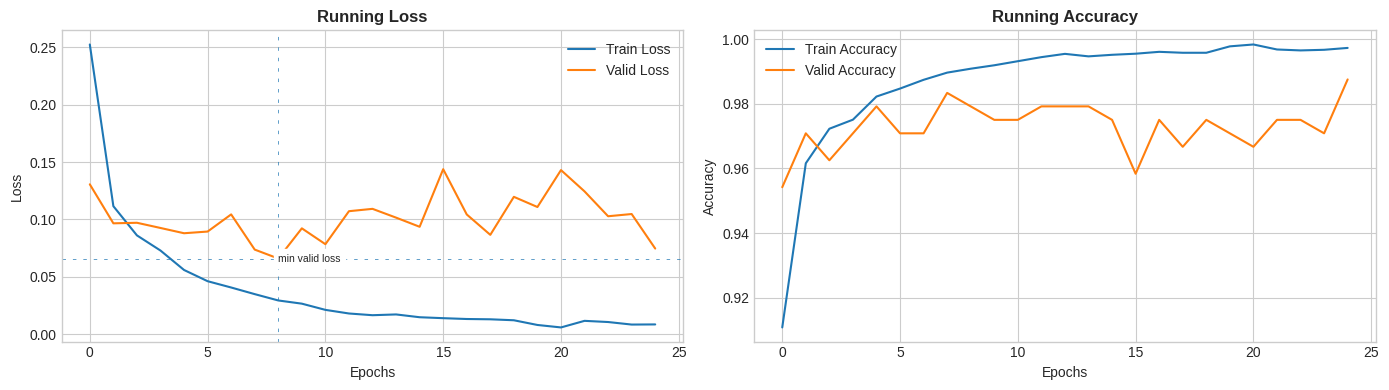

In [17]:
# fit() writes the per-epoch history to outputs/CSVs/<model_name>.csv, where
# model_name = type(model).__name__.lower() — for resnet18 that's 'resnet'
# (torchvision's class is named `ResNet`), not 'resnet18'.
plot_summary(f'outputs/CSVs/{type(resnet18).__name__.lower()}.csv')

### Testing on the held-out test set

`test_set` was created above but never actually used — mirrors the pattern
from the companion `3_evaluate_results.ipynb`: get predictions on train and
test, accuracy, a confusion-matrix heatmap, and per-class
accuracy/recall/precision/F1 via the inlined `utils` functions, plus a
`sklearn` classification report for a quick, standard summary.

In [ ]:
train_eval_dl = DataLoader(train_set, batch_size=128)
test_dl = DataLoader(test_set, batch_size=40)

train_preds = get_all_preds(resnet18, train_eval_dl)
test_preds = get_all_preds(resnet18, test_dl)

train_correct = get_num_correct(train_preds, torch.as_tensor(train_set.targets, device=device))
test_correct = get_num_correct(test_preds, torch.as_tensor(test_set.targets, device=device))

print(f'Train Correct: {train_correct:5}\tTrain Accuracy: {(100*train_correct/len(train_set)):5.2f}%')
print(f'Test Correct: {test_correct:6}\tTest Accuracy: {(100*test_correct/len(test_set)):6.2f}%')

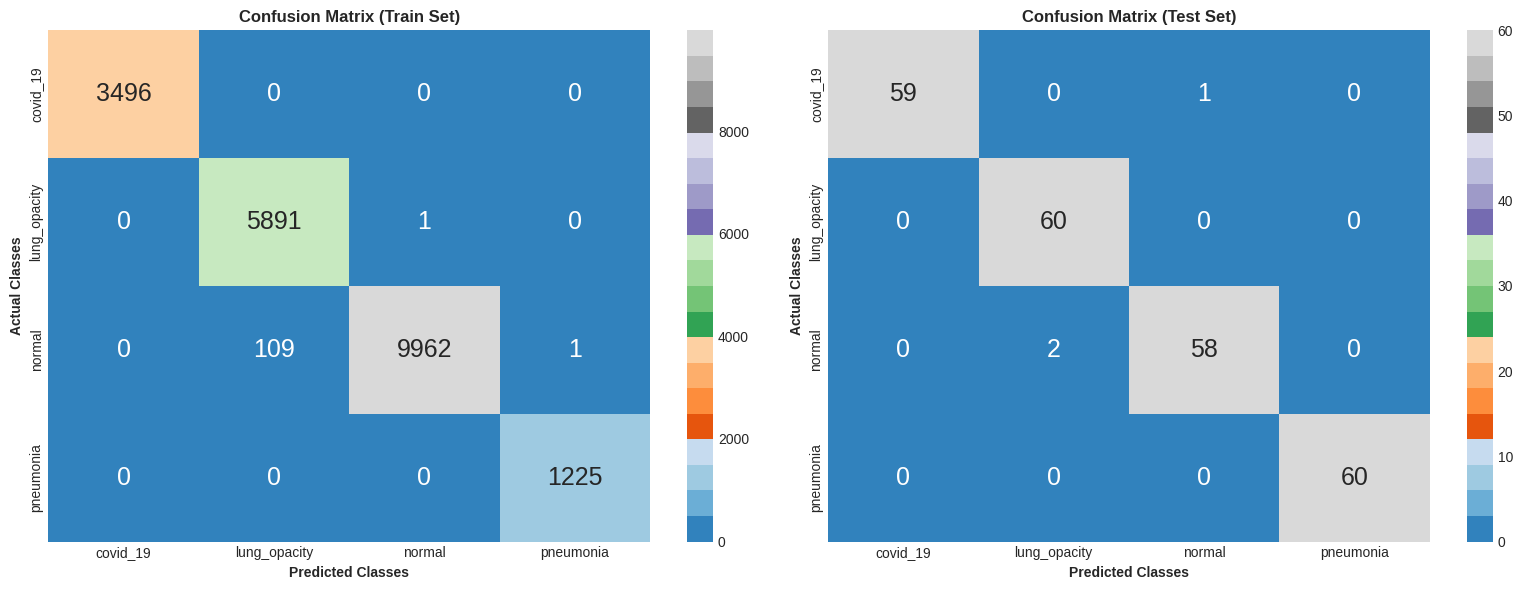

In [19]:
train_confmat = get_confmat(train_set.targets, train_preds)
test_confmat = get_confmat(test_set.targets, test_preds)
plot_confmat(train_confmat, test_confmat, train_set.classes, type(resnet18).__name__.lower())

In [ ]:
results = get_results(test_confmat, test_set.classes)
results

In [21]:
# Same numbers, as a standard sklearn report for a quick sanity cross-check.
y_true = np.array(test_set.targets)
y_pred = test_preds.argmax(dim=1).cpu().numpy()
print(classification_report(y_true, y_pred, target_names=test_set.classes))

              precision    recall  f1-score   support

    covid_19       1.00      0.98      0.99        60
lung_opacity       0.97      1.00      0.98        60
      normal       0.98      0.97      0.97        60
   pneumonia       1.00      1.00      1.00        60

    accuracy                           0.99       240
   macro avg       0.99      0.99      0.99       240
weighted avg       0.99      0.99      0.99       240



### GradCAM visualization

Localizes which part of the X-ray the trained ResNet-18 is basing its
prediction on, using the last conv block (`resnet18.layer4[-1]`) as the
target layer — the standard choice for ResNet-style GradCAM.

True: pneumonia  |  GradCAM computed for: pneumonia


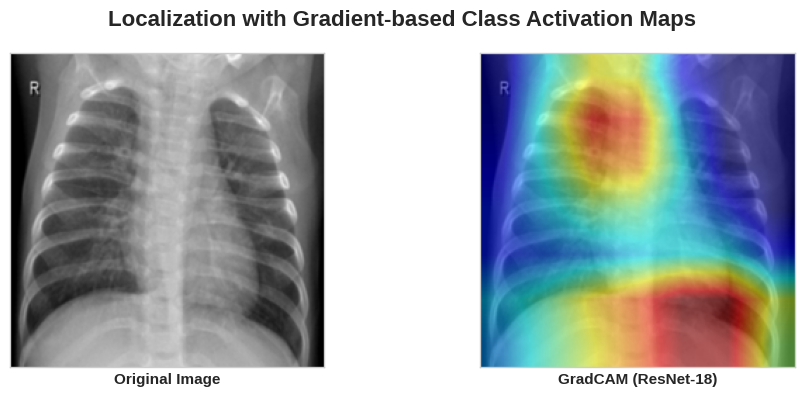

In [22]:
warnings.filterwarnings('ignore', category=UserWarning)

resnet_target_layer = resnet18.layer4[-1]


def gradcam_on_sample(model, target_layer, dataset, index, label=None):
    """Runs GradCAM on dataset[index] and returns (image_tensor, true_label,
    predicted_label, cam_mask)."""
    image, true_label = dataset[index]
    image = image.unsqueeze(dim=0).to(device)

    cam_obj = GradCAM(model=model, target_layer=target_layer)
    pred_label, cam = cam_obj(image, label)

    return image, true_label, pred_label, cam


# a single example (a random index, rather than a hard-coded one, so this
# still works whatever size the test set ends up being)
sample_index = int(np.random.randint(len(test_set)))
image, true_label, pred_label, cam = gradcam_on_sample(resnet18, resnet_target_layer, test_set, index=sample_index)
print(f'True: {test_set.classes[true_label]}  |  GradCAM computed for: {test_set.classes[pred_label]}')

plot_gradcam(image, {'GradCAM (ResNet-18)': cam}, filename='resnet18_sample.png')

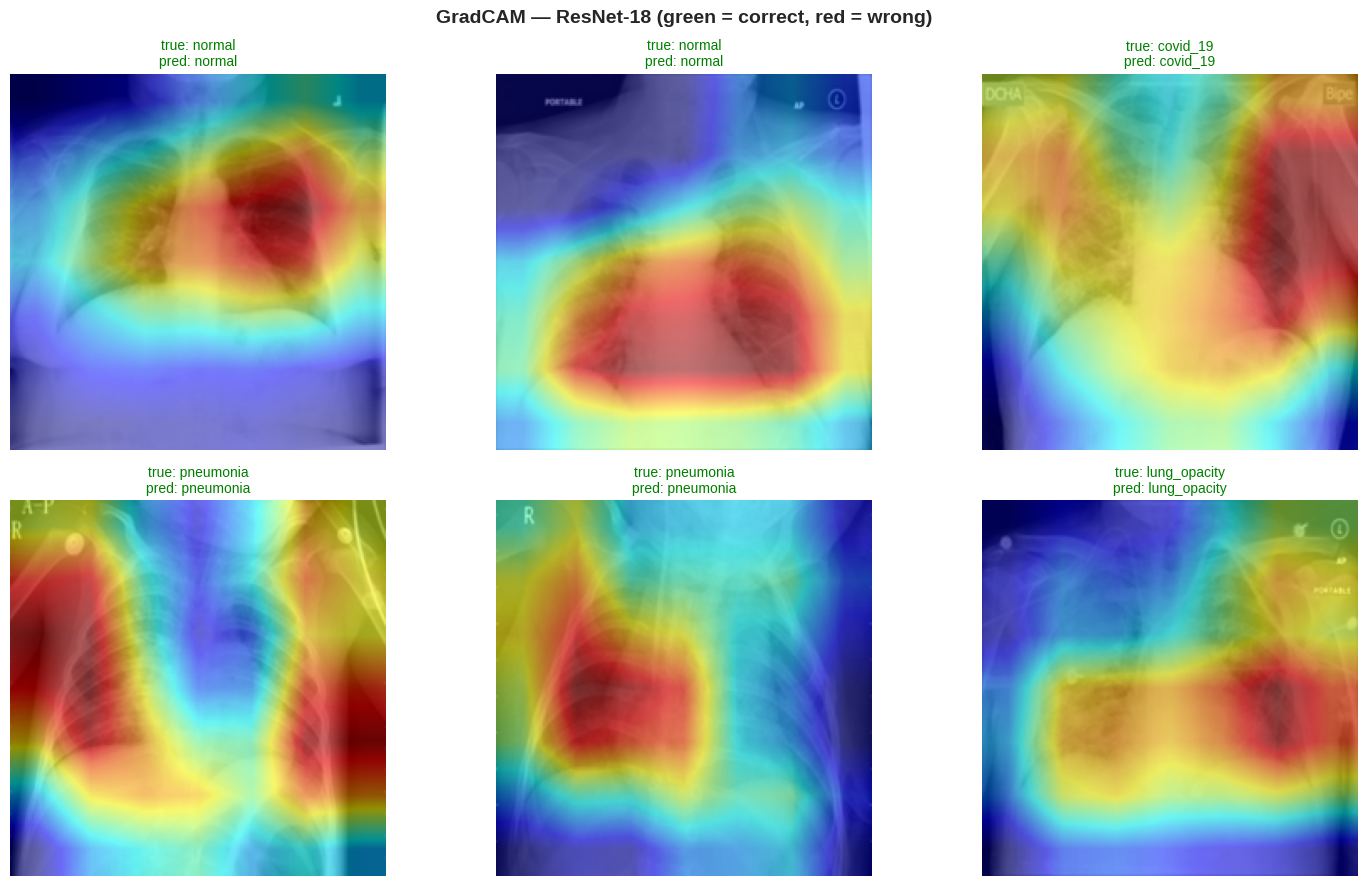

In [23]:
# A small grid across a few random test images, each labeled with its
# true class and what the model predicted (mismatches are easy to spot).
sample_indices = np.random.choice(len(test_set), size=6, replace=False)

_use_style_fn = _use_style if '_use_style' in globals() else None
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, idx in zip(axes.flatten(), sample_indices):
    image, true_label, pred_label, cam = gradcam_on_sample(
        resnet18, resnet_target_layer, test_set, index=int(idx)
    )
    overlay = apply_mask(deprocess_image(image), cam)[:, :, ::-1]  # BGR -> RGB

    ax.imshow(overlay)
    ax.axis('off')
    color = 'green' if pred_label == true_label else 'red'
    ax.set_title(
        f'true: {test_set.classes[true_label]}\npred: {test_set.classes[pred_label]}',
        color=color, fontsize=10
    )

fig.suptitle('GradCAM — ResNet-18 (green = correct, red = wrong)', fontweight='bold', fontsize=14)
plt.tight_layout()
fig.savefig('outputs/gradcam/resnet18_grid.png')
plt.show()

### Is the model actually looking at the lungs?

GradCAM tells you *where* the model looked, but not whether that's actually
meaningful. A well-known failure mode in COVID-19 chest X-ray classifiers
(see DeGrave et al., *"AI for radiographic COVID-19 detection selects
shortcuts over signal"*, Nature Machine Intelligence 2021) is that models
trained on datasets pooled from different hospitals/sources learn to key
off spurious cues — text markers, borders, scan-position artifacts — rather
than actual lung pathology, while still reaching high accuracy.

The COVID-19 Radiography Database this notebook downloads via `kagglehub`
ships a `masks/` folder of lung segmentation masks alongside each raw image
(the `images/`+`masks/` nesting `split_dataset()` above already detects, but
only carries the images through the split). This section uses those masks
as an independent, dataset-provided ground truth for "where the lungs
actually are," and scores each GradCAM heatmap by how much of its attention
actually falls inside the lungs — turning the GradCAM cells above from a
qualitative picture into a quantitative faithfulness check.

If masks aren't available for this dataset release (older releases didn't
ship them), the cells below say so and skip gracefully rather than failing.

In [24]:
# --- Locate each split image's original raw folder + lung mask ------------
# split_dataset() copies files out of CLASS_SOURCE_DIR/<raw class>/images/
# into <root_dir>/<split>/<class>/, but never touches the sibling masks/
# folder — so the raw source directory (still intact, since it was copied
# from, not moved) is exactly where each image's mask still lives.

def find_lung_mask(image_path):
    """Given a path into the *split* dataset (e.g.
    '.../test/covid_19/COVID-101.png'), returns the matching lung-mask path
    from the raw CLASS_SOURCE_DIR, or None if this dataset release doesn't
    ship masks (or the mask is missing for this particular image)."""
    if CLASS_SOURCE_DIR is None:
        return None

    class_name = os.path.basename(os.path.dirname(image_path))
    raw_dir = CLASS_TO_RAW_DIR.get(class_name)
    if raw_dir is None:
        return None

    filename = os.path.basename(image_path)
    mask_path = os.path.join(CLASS_SOURCE_DIR, raw_dir, 'masks', filename)
    return mask_path if os.path.isfile(mask_path) else None


def load_lung_mask(mask_path, size=(224, 224)):
    """Loads a lung mask and resizes/binarizes it to match the (224, 224)
    resolution GradCAM heatmaps are computed at."""
    mask = Image.open(mask_path).convert('L').resize(size, Image.NEAREST)
    mask = np.array(mask)
    return mask > 127  # boolean array, True = inside the lungs


# quick check: how many of the current test set's images actually have a
# lung mask available in this dataset release?
sample_paths = [p for p, _ in test_set.samples[:50]]
n_with_mask = sum(find_lung_mask(p) is not None for p in sample_paths)
print(f'{n_with_mask}/{len(sample_paths)} sampled test images have a lung mask available.')
if n_with_mask == 0:
    print(
        'No lung masks found for this dataset release/location — the '
        'faithfulness cells below will report 0 usable samples. Nothing '
        'else in the notebook depends on this.'
    )

50/50 sampled test images have a lung mask available.


In [25]:
# --- Faithfulness metric: how much of the model's attention falls inside the lungs? ---
def gradcam_lung_faithfulness(cam, lung_mask, activation_threshold=0.5):
    """`cam` is a GradCAM heatmap in [0, 1] (224, 224); `lung_mask` is the
    boolean lung mask at the same resolution. Thresholds the heatmap to get
    the region the model is "attending to", then reports:

      - in_lung_fraction: of the pixels the model attended to, what
        fraction fall inside the lungs. This is the headline faithfulness
        score — low values mean the model is basing its decision on
        something outside the lungs (a shortcut).
      - lung_coverage: of the lung area itself, what fraction got
        attended to (a secondary, less critical stat — a model can be
        faithful while only focusing on one small diseased region).
    """
    attended = cam >= activation_threshold
    attended_pixels = int(attended.sum())
    lung_pixels = int(lung_mask.sum())

    if attended_pixels == 0 or lung_pixels == 0:
        return {
            'in_lung_fraction': float('nan'),
            'lung_coverage': float('nan'),
            'attended_pixels': attended_pixels,
            'lung_pixels': lung_pixels,
        }

    overlap = int((attended & lung_mask).sum())
    return {
        'in_lung_fraction': overlap / attended_pixels,
        'lung_coverage': overlap / lung_pixels,
        'attended_pixels': attended_pixels,
        'lung_pixels': lung_pixels,
    }


def gradcam_with_faithfulness(model, target_layer, dataset, index, label=None):
    """Like gradcam_on_sample(), but also returns the lung-mask
    faithfulness score for that sample (None if no mask is available)."""
    image, true_label, pred_label, cam = gradcam_on_sample(
        model, target_layer, dataset, index, label
    )
    image_path, _ = dataset.samples[index]
    mask_path = find_lung_mask(image_path)

    score = None
    lung_mask = None
    if mask_path is not None:
        lung_mask = load_lung_mask(mask_path)
        score = gradcam_lung_faithfulness(cam, lung_mask)

    return image, true_label, pred_label, cam, lung_mask, score

[1/5] True: pneumonia     Pred: pneumonia     In-lung attention: 19.0%  Lung coverage: 73.5%
[2/5] True: lung_opacity  Pred: lung_opacity  In-lung attention: 33.4%  Lung coverage: 32.6%
[3/5] True: lung_opacity  Pred: lung_opacity  In-lung attention: 42.2%  Lung coverage: 62.1%
[4/5] True: pneumonia     Pred: pneumonia     In-lung attention: 37.0%  Lung coverage: 79.8%
[5/5] True: normal        Pred: normal        In-lung attention: 38.3%  Lung coverage: 75.9%


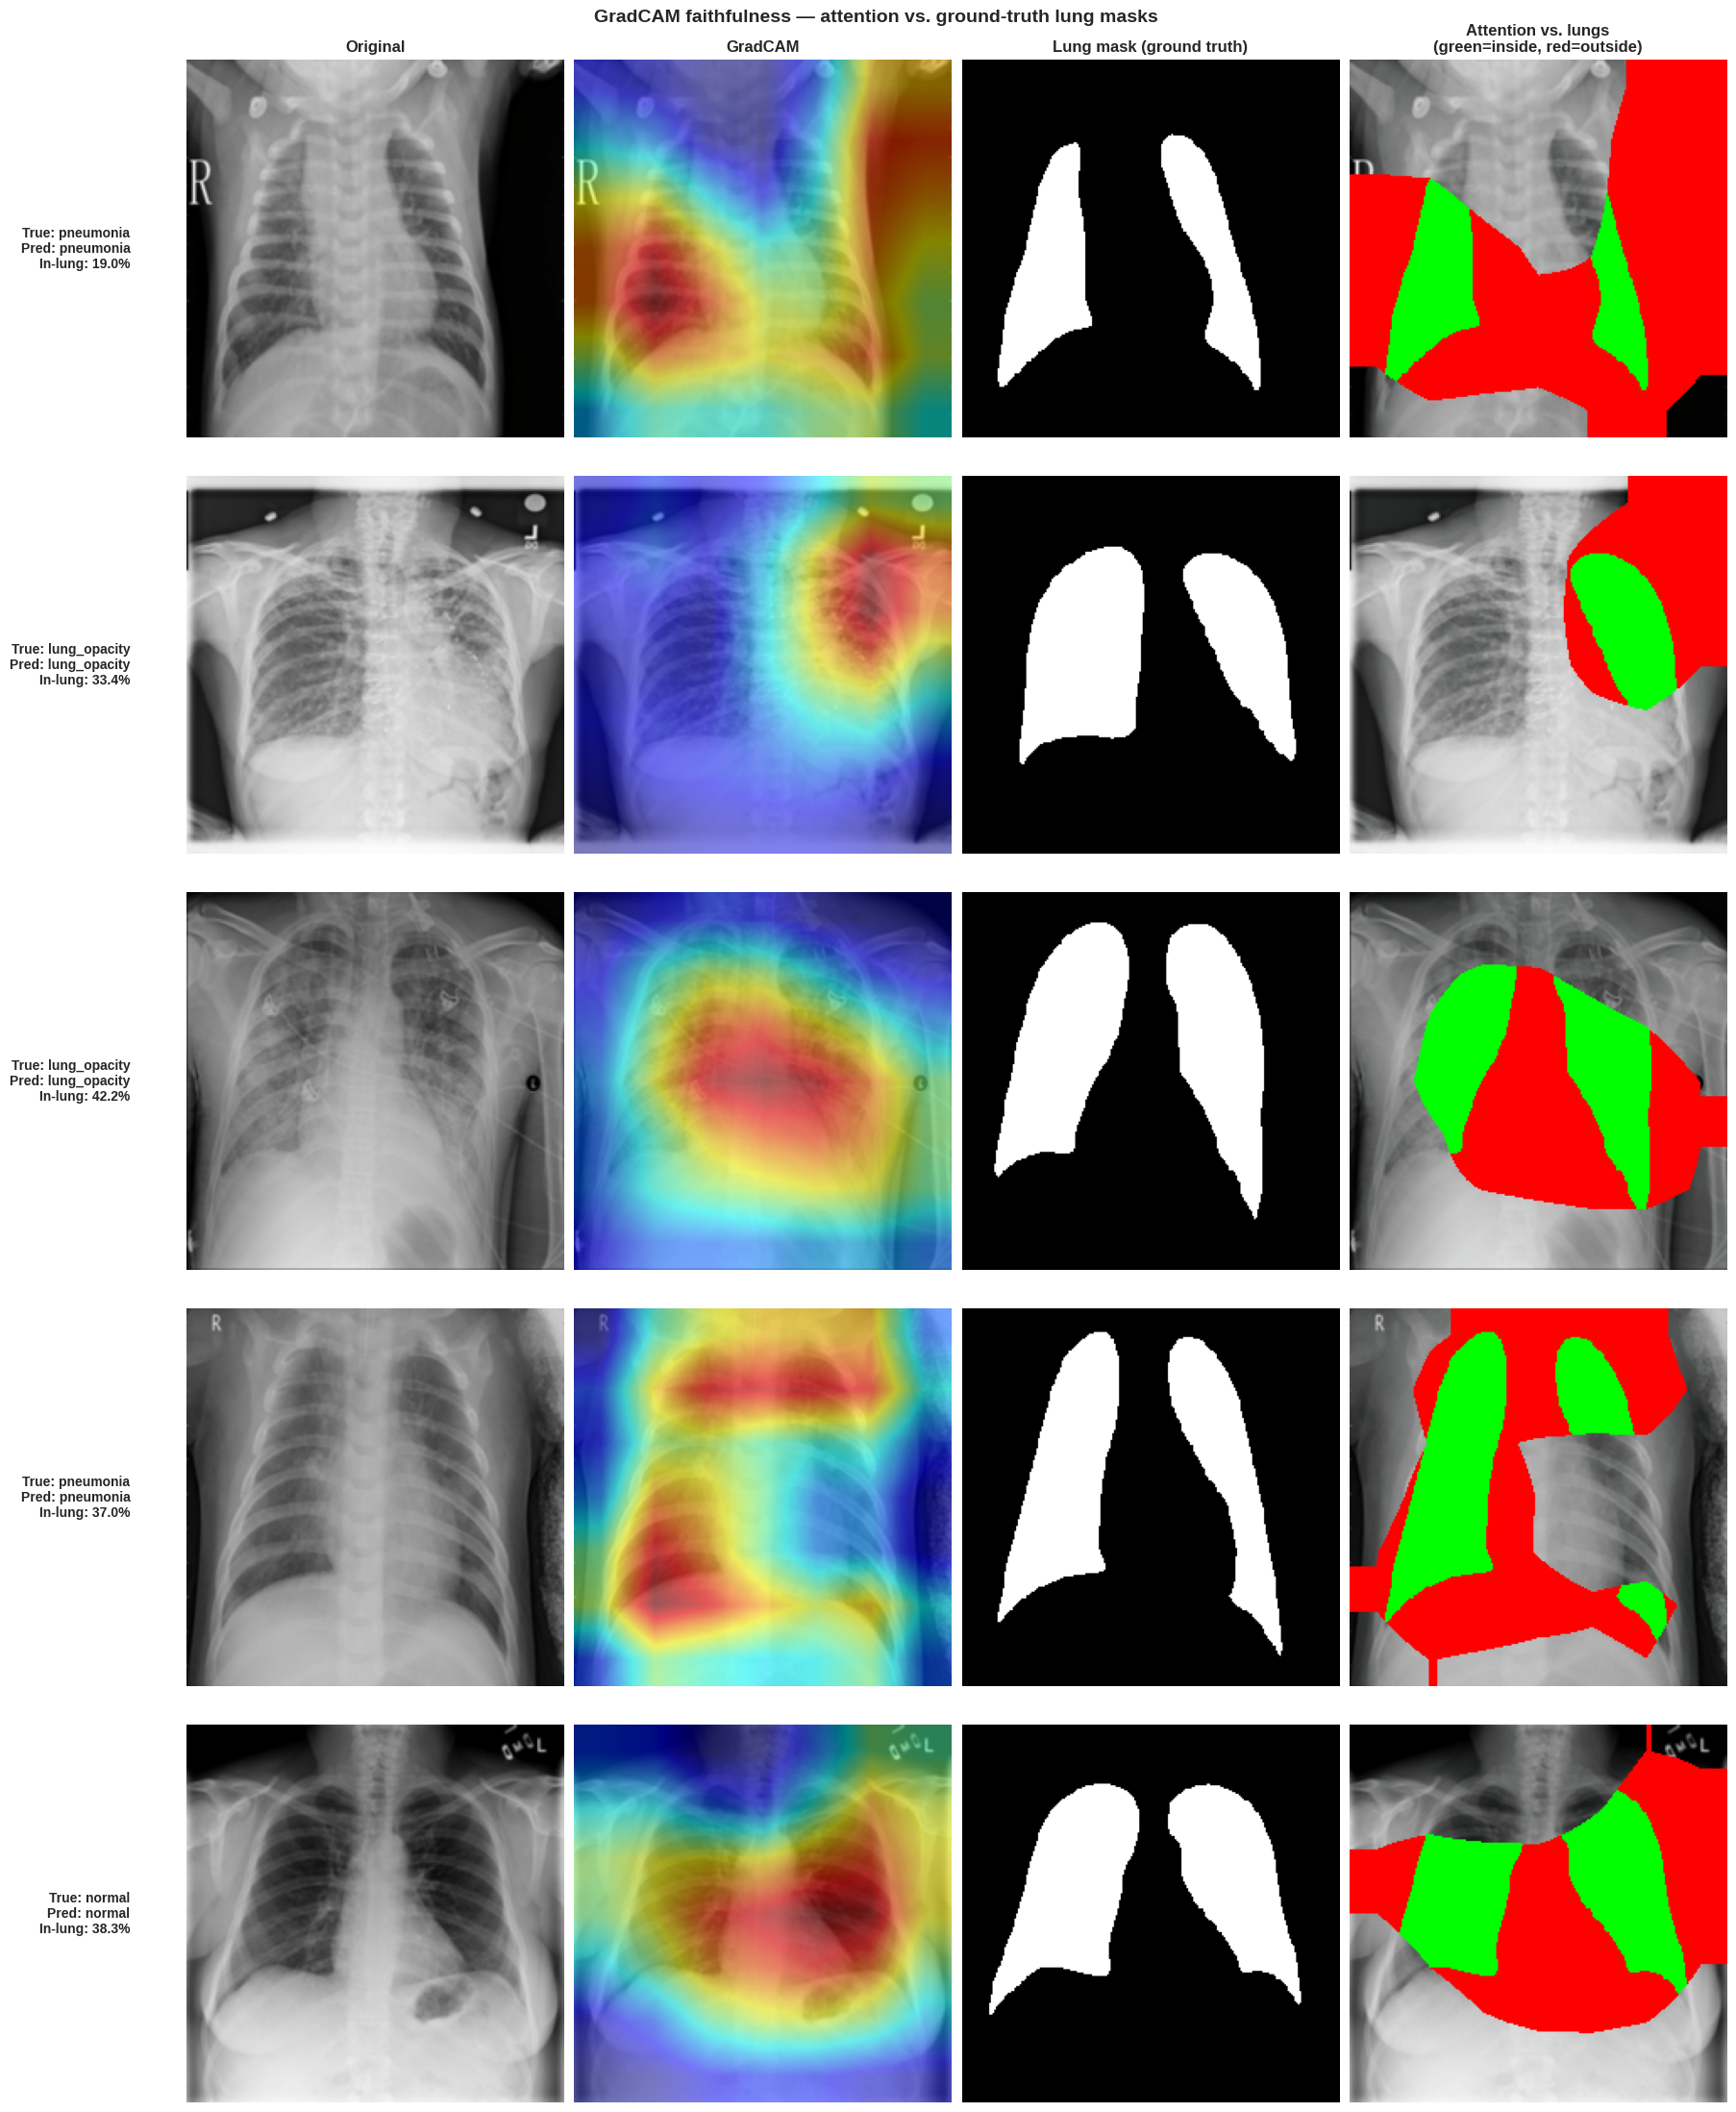

In [28]:
# --- Worked examples: original | GradCAM | lung mask | attention-vs-lung overlay ---
masked_indices = [
    i for i, (p, _) in enumerate(test_set.samples) if find_lung_mask(p) is not None
]

N_EXAMPLES = 5

if not masked_indices:
    print('No test images with an available lung mask — skipping the worked examples.')
else:
    n_show = min(N_EXAMPLES, len(masked_indices))
    example_indices = np.random.choice(masked_indices, size=n_show, replace=False)

    fig, axes = plt.subplots(n_show, 4, figsize=(18, 4.5 * n_show))
    if n_show == 1:
        axes = axes.reshape(1, 4)  # keep indexing consistent for a single row

    col_titles = ['Original', 'GradCAM', 'Lung mask (ground truth)',
                  'Attention vs. lungs\n(green=inside, red=outside)']

    for row, idx in enumerate(example_indices):
        image, true_label, pred_label, cam, lung_mask, score = gradcam_with_faithfulness(
            resnet18, resnet_target_layer, test_set, index=int(idx)
        )
        deproc = deprocess_image(image)
        gradcam_overlay = apply_mask(deproc, cam)[:, :, ::-1]  # BGR -> RGB

        attended = cam >= 0.5
        verdict_overlay = np.array(deproc * 255, dtype=np.uint8).copy()
        verdict_overlay[attended & lung_mask] = [0, 255, 0]
        verdict_overlay[attended & ~lung_mask] = [255, 0, 0]

        panels = [deproc, gradcam_overlay, lung_mask, verdict_overlay]
        for col, (panel, cmap) in enumerate(zip(panels, [None, None, 'gray', None])):
            ax = axes[row, col]
            ax.imshow(panel, cmap=cmap)
            ax.axis('off')
            if row == 0:
                ax.set_title(col_titles[col], fontweight='bold')

        axes[row, 0].text(
            -0.15, 0.5,
            f'True: {test_set.classes[true_label]}\nPred: {test_set.classes[pred_label]}\n'
            f'In-lung: {score["in_lung_fraction"]:.1%}',
            transform=axes[row, 0].transAxes, ha='right', va='center',
            fontsize=10, fontweight='bold'
        )

        print(
            f'[{row+1}/{n_show}] True: {test_set.classes[true_label]:12s}  '
            f'Pred: {test_set.classes[pred_label]:12s}  '
            f'In-lung attention: {score["in_lung_fraction"]:.1%}  '
            f'Lung coverage: {score["lung_coverage"]:.1%}'
        )

    fig.suptitle('GradCAM faithfulness — attention vs. ground-truth lung masks', fontweight='bold', fontsize=14)
    plt.tight_layout()
    fig.savefig('outputs/gradcam/resnet18_lung_faithfulness_examples.png')
    plt.show()

Mean in-lung attention across 60 test samples: 33.7%
             mean  count
correct                 
False    0.289539      2
True     0.338678     58


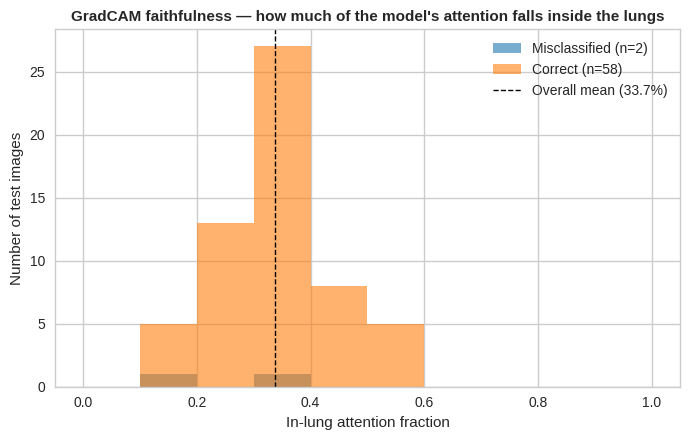

In [27]:
# --- Aggregate faithfulness score across many test samples ---
# A single example is anecdotal; averaging over as many test images as have
# masks available gives an actual per-model faithfulness number, and lets
# us check whether misclassified images tend to be the ones where the
# model was looking in the wrong place.
n_samples = min(60, len(masked_indices)) if masked_indices else 0
eval_indices = list(np.random.choice(masked_indices, size=n_samples, replace=False)) if n_samples else []

records = []
for idx in eval_indices:
    _, true_label, pred_label, _, _, score = gradcam_with_faithfulness(
        resnet18, resnet_target_layer, test_set, index=int(idx)
    )
    if score is not None and not np.isnan(score['in_lung_fraction']):
        records.append({
            'correct': pred_label == true_label,
            'in_lung_fraction': score['in_lung_fraction'],
        })

if not records:
    print('No usable (mask + non-empty GradCAM activation) samples to aggregate over.')
else:
    faithfulness_df = pd.DataFrame(records)
    overall_mean = faithfulness_df['in_lung_fraction'].mean()
    print(f'Mean in-lung attention across {len(faithfulness_df)} test samples: {overall_mean:.1%}')
    print(faithfulness_df.groupby('correct')['in_lung_fraction'].agg(['mean', 'count']))

    _use_style('seaborn-whitegrid')
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for correct, group in faithfulness_df.groupby('correct'):
        ax.hist(
            group['in_lung_fraction'], bins=10, range=(0, 1), alpha=0.6,
            label=f'{"Correct" if correct else "Misclassified"} (n={len(group)})'
        )
    ax.axvline(overall_mean, color='black', linestyle='--', linewidth=1,
               label=f'Overall mean ({overall_mean:.1%})')
    ax.set_xlabel('In-lung attention fraction')
    ax.set_ylabel('Number of test images')
    ax.set_title('GradCAM faithfulness — how much of the model\'s attention falls inside the lungs',
                 fontweight='bold', fontsize=11)
    ax.legend()
    plt.tight_layout()
    fig.savefig('outputs/gradcam/lung_faithfulness_histogram.png')
    plt.show()